<a href="https://colab.research.google.com/github/rdianap/Midterm-Wine-Quality/blob/main/Nabila_Rahayu_2404010015_UTS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS – Klasifikasi Kualitas Anggur (Wine Quality)

**Tujuan:** membangun model klasifikasi untuk memprediksi `quality` anggur dari fitur kimiawinya menggunakan `data_training.csv`, lalu menerapkan model pada `data_testing.csv` dan menyimpan hasilnya (`Id` dan `Quality`) dalam format CSV.

**Alur pengerjaan**
1. Persiapan data (impor library, memuat data)
2. Eksplorasi dan pembersihan data (missing value, duplikat, outlier, skala fitur)
3. Pembuatan model (perbandingan beberapa algoritma, tuning, evaluasi)
4. Penyimpanan model dan prediksi data uji
5. Kesimpulan

## 1. Persiapan Data

In [41]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from IPython.display import FileLink, display
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

Data dimuat dari folder `Dataset UTS`. Ubah `DATA_DIR` bila lokasi folder berbeda di komputer Anda.

In [42]:
DATA_DIR = "Dataset UTS"

train = pd.read_csv("data_training.csv")
test = pd.read_csv("data_testing.csv")
template = pd.read_csv("hasilprediksi_3digitNIMterakhir.csv", sep=";")

print("Ukuran data training :", train.shape)
print("Ukuran data testing  :", test.shape)
print("Kolom template output:", template.columns.tolist())
print()
print(train.head())

Ukuran data training : (857, 13)
Ukuran data testing  : (286, 12)
Kolom template output: ['Id', 'Quality']

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.3             0.740         0.08             1.7      0.094   
1            8.1             0.575         0.22             2.1      0.077   
2           10.1             0.430         0.40             2.6      0.092   
3           12.9             0.500         0.55             2.8      0.072   
4            8.4             0.360         0.32             2.2      0.081   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 10.0                  45.0  0.99576  3.24       0.50   
1                 12.0                  65.0  0.99670  3.29       0.51   
2                 13.0                  52.0  0.99834  3.22       0.64   
3                  7.0                  24.0  1.00012  3.09       0.68   
4                 32.0                  79.0  0.99640

**Interpretasi:** data training berisi fitur kimiawi, kolom target `quality`, dan kolom `Id`. Data testing memiliki kolom yang sama **tanpa** `quality`. Kolom `Id` hanyalah pengenal baris sehingga tidak dipakai sebagai fitur (memakainya bisa membuat model belajar pola yang tidak bermakna). Template output memakai pemisah titik koma (`;`), jadi file hasil nanti ditulis dengan format yang sama.

## 2. Eksplorasi dan Pembersihan Data

### 2.1 Tipe data dan missing value

In [43]:
print(train.dtypes)
print()
print("Missing value (training):", train.isna().sum().sum())
print("Missing value (testing) :", test.isna().sum().sum())

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object

Missing value (training): 0
Missing value (testing) : 0


**Interpretasi:** semua fitur bertipe numerik dan **tidak ada missing value** pada kedua dataset, sehingga imputasi maupun penghapusan baris tidak diperlukan.

### 2.2 Distribusi target `quality`

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64

quality
3     0.7 %
4     3.0 %
5    42.2 %
6    39.8 %
7    12.7 %
8     1.5 %
Name: count, dtype: object


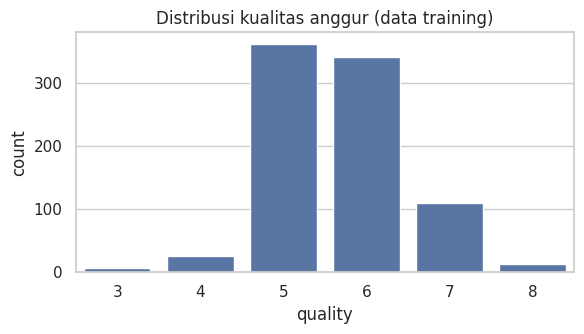

In [44]:
counts = train["quality"].value_counts().sort_index()
print(counts)
print()
print((counts / len(train) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(6, 3.5))
sns.countplot(x="quality", data=train, color="#4c72b0")
plt.title("Distribusi kualitas anggur (data training)")
plt.tight_layout()
plt.show()

**Interpretasi:** kelas bersifat **tidak seimbang**. Hampir seluruh data berada di kualitas 5 dan 6, sedangkan kualitas 3, 4, dan 8 sangat jarang. Konsekuensinya, model cenderung sulit menebak kelas langka, dan akurasi sebaiknya dibaca bersama confusion matrix. Kelas dibiarkan apa adanya (tanpa oversampling) karena jumlah data kecil dan oversampling berisiko menduplikasi noise.

### 2.3 Statistik deskriptif dan skala fitur

In [45]:
features = [c for c in train.columns if c not in ["quality", "Id"]]
print(train[features].describe().T[["min", "max", "mean", "std"]].round(4))

                         min       max     mean      std
fixed acidity         4.6000   15.6000   8.2620   1.7020
volatile acidity      0.1200    1.5800   0.5294   0.1792
citric acid           0.0000    1.0000   0.2674   0.1951
residual sugar        0.9000   15.5000   2.5062   1.2935
chlorides             0.0120    0.6110   0.0868   0.0487
free sulfur dioxide   1.0000   68.0000  15.7830  10.3004
total sulfur dioxide  6.0000  278.0000  45.9784  31.6921
density               0.9901    1.0032   0.9967   0.0019
pH                    2.7400    4.0100   3.3131   0.1521
sulphates             0.3900    2.0000   0.6567   0.1674
alcohol               8.4000   14.0000  10.4303   1.0670


**Interpretasi:** rentang antar fitur sangat berbeda. `total sulfur dioxide` mencapai ratusan, sedangkan `density` hanya berkisar sekitar 0,99–1,00. Karena itu **normalisasi (StandardScaler) diperlukan** untuk model yang sensitif terhadap skala (Regresi Logistik, KNN, SVM). Model berbasis pohon (Random Forest, Extra Trees, Gradient Boosting) tidak terpengaruh skala, sehingga tidak memerlukannya. Scaler dipasang di dalam `Pipeline` agar tidak terjadi kebocoran data dari fold validasi.

### 2.4 Outlier

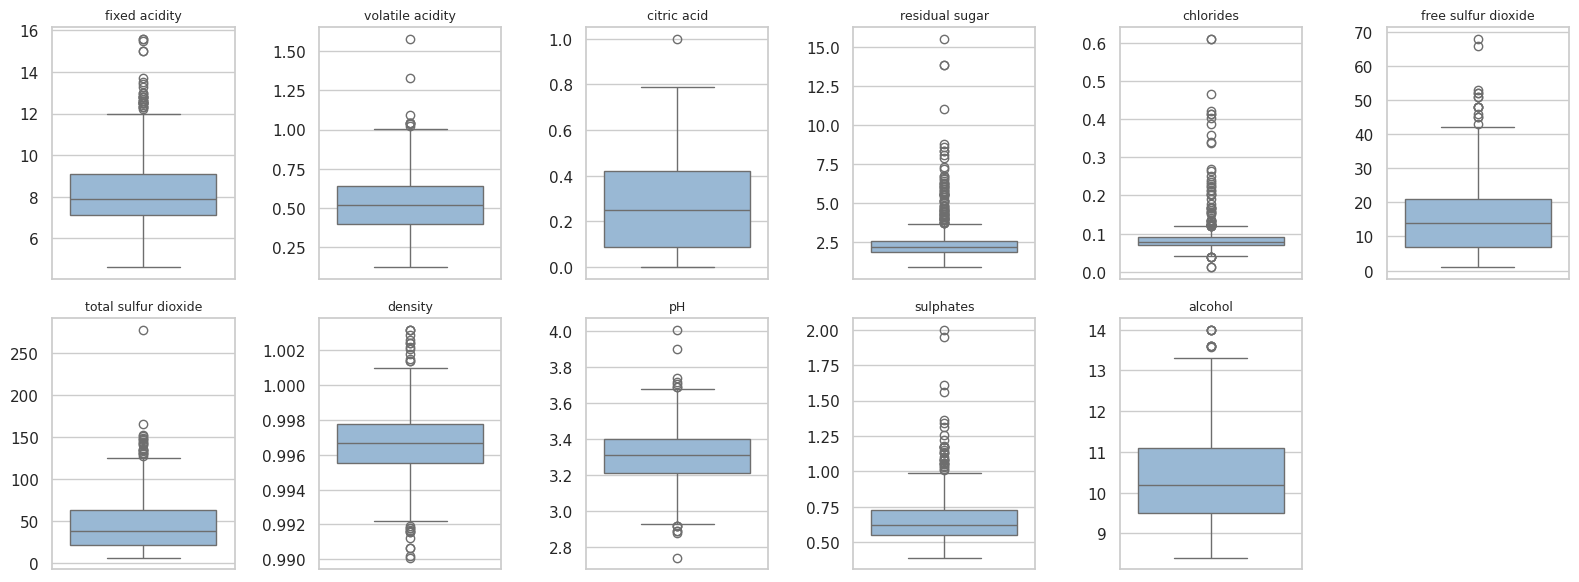

Jumlah outlier (aturan 1,5 x IQR) per fitur:
residual sugar          76
chlorides               59
sulphates               31
fixed acidity           30
density                 25
total sulfur dioxide    19
free sulfur dioxide     15
pH                      14
alcohol                  9
volatile acidity         8
citric acid              1
dtype: int64


In [46]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=train[col], ax=ax, color="#8fb8de")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Q1, Q3 = train[features].quantile(0.25), train[features].quantile(0.75)
IQR = Q3 - Q1
n_out = ((train[features] < Q1 - 1.5 * IQR) | (train[features] > Q3 + 1.5 * IQR)).sum()
print("Jumlah outlier (aturan 1,5 x IQR) per fitur:")
print(n_out.sort_values(ascending=False))

**Interpretasi:** beberapa fitur, terutama `residual sugar`, `chlorides`, `sulphates`, dan `fixed acidity`, memiliki cukup banyak titik di luar batas IQR. Nilai tersebut masih wajar secara kimiawi (bukan kesalahan input) dan bisa jadi justru informatif bagi kualitas, sehingga **outlier tidak dibuang**. Model berbasis pohon juga relatif tahan terhadap outlier, dan SVM dengan data terstandarisasi masih dapat menanganinya dengan baik.

### 2.5 Duplikat dan korelasi

Baris duplikat (semua fitur + quality, tanpa Id): 76
Id yang muncul di training dan testing sekaligus : 0


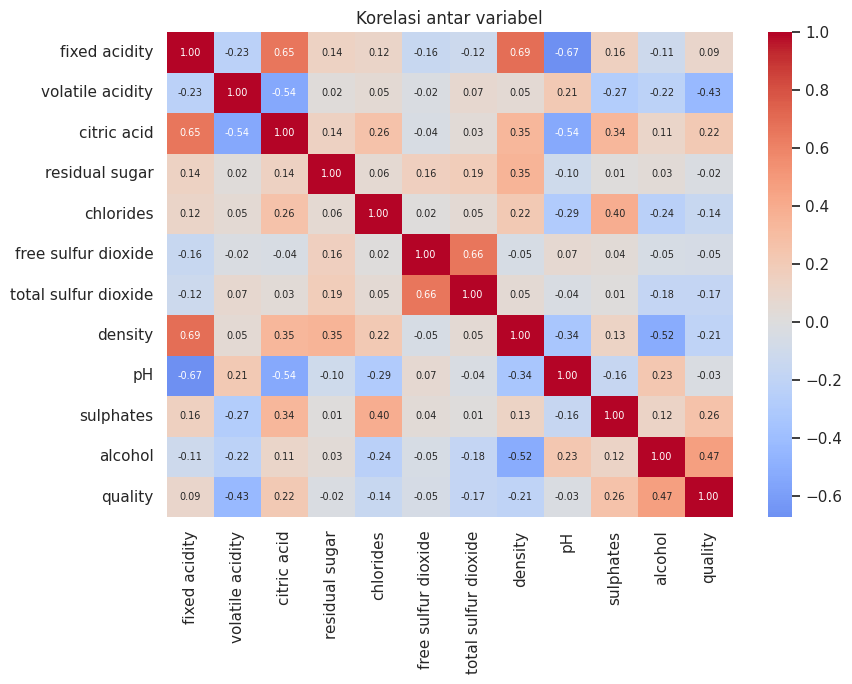

alcohol                 0.474
sulphates               0.261
citric acid             0.221
fixed acidity           0.093
residual sugar         -0.021
pH                     -0.033
free sulfur dioxide    -0.055
chlorides              -0.145
total sulfur dioxide   -0.173
density                -0.208
volatile acidity       -0.430
Name: quality, dtype: float64


In [47]:
dup_all = train.drop(columns="Id").duplicated().sum()
print("Baris duplikat (semua fitur + quality, tanpa Id):", dup_all)
print("Id yang muncul di training dan testing sekaligus :", len(set(train["Id"]) & set(test["Id"])))

plt.figure(figsize=(9, 7))
sns.heatmap(train[features + ["quality"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Korelasi antar variabel")
plt.tight_layout()
plt.show()

print(train[features + ["quality"]].corr()["quality"].drop("quality").sort_values(ascending=False).round(3))

**Interpretasi:**
- Terdapat sejumlah baris duplikat. Ini lazim pada dataset Wine Quality (sampel berbeda dengan hasil ukur identik). Baris ini **dipertahankan**, tetapi saat validasi silang saya mengelompokkan baris yang identik ke dalam fold yang sama (lihat bagian 3) agar skor tidak terlalu optimis akibat baris kembar ada di data latih sekaligus data validasi.
- Tidak ada `Id` yang tumpang tindih antara training dan testing.
- `alcohol` memiliki korelasi positif terkuat dengan `quality`, sedangkan `volatile acidity` memiliki korelasi negatif terkuat. `citric acid` dan `sulphates` berkorelasi positif lemah, sedangkan `density` dan `total sulfur dioxide` berkorelasi negatif lemah. Heatmap juga menunjukkan beberapa fitur saling berkorelasi, yang tidak menjadi masalah bagi model pohon.

## 3. Pembuatan Model

### 3.1 Skema validasi
Evaluasi memakai **Stratified Group 5-Fold Cross-Validation**: stratifikasi menjaga proporsi kelas, dan pengelompokan menjaga baris duplikat tetap satu fold. Kelas 3 hanya punya 6 sampel, maka kelas 3 digabung dengan kelas 4 **hanya untuk keperluan stratifikasi** (label asli tetap dipakai untuk pelatihan dan penilaian).

In [48]:
X = train[features]
y = train["quality"]
groups = pd.util.hash_pandas_object(X, index=False).values   # baris identik -> grup yang sama

cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
          .split(X, y.clip(lower=4), groups))
print("Jumlah fold:", len(cv))

Jumlah fold: 5


### 3.2 Perbandingan beberapa algoritma

In [49]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=15)":          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(C=3)),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees":         ExtraTreesClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
}

rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"Model": name, "Akurasi rata-rata": s.mean(), "Std": s.std()})

hasil = pd.DataFrame(rows).sort_values("Akurasi rata-rata", ascending=False).reset_index(drop=True)
print(hasil.round(4).to_string(index=False))

              Model  Akurasi rata-rata    Std
          SVM (RBF)             0.5937 0.0312
        Extra Trees             0.5901 0.0359
      Random Forest             0.5833 0.0335
Logistic Regression             0.5759 0.0477
         KNN (k=15)             0.5434 0.0398
  Gradient Boosting             0.5227 0.0336


**Interpretasi:** pada konfigurasi bawaan, SVM, Extra Trees, Random Forest, dan Regresi Logistik berada pada level yang hampir sama (selisihnya lebih kecil dari simpangan baku antar fold), sedangkan KNN dan Gradient Boosting tertinggal. Karena selisih di antara empat teratas tipis, ketiga kandidat terkuat dari keluarga berbeda (SVM, Extra Trees, Random Forest) dilanjutkan ke tahap tuning agar perbandingannya adil.

### 3.3 Tuning hyperparameter

In [50]:
grid_trees = {
    "max_features": ["sqrt", 0.5, 0.7],
    "min_samples_leaf": [1, 2, 3],
    "class_weight": [None, "balanced_subsample"],
}
grid_svm = {
    "svc__C": [1, 3, 10, 30],
    "svc__gamma": ["scale", 0.03, 0.3],
    "svc__class_weight": [None, "balanced"],
}

searches = {
    "Extra Trees":   GridSearchCV(ExtraTreesClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
                                  grid_trees, cv=cv, scoring="accuracy", n_jobs=1),
    "Random Forest": GridSearchCV(RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
                                  grid_trees, cv=cv, scoring="accuracy", n_jobs=1),
    "SVM (RBF)":     GridSearchCV(make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)),
                                  grid_svm, cv=cv, scoring="accuracy", n_jobs=-1),
}

for name, gs in searches.items():
    gs.fit(X, y)
    print(f"{name:14s} CV acc = {gs.best_score_:.4f} | {gs.best_params_}")

best_name = max(searches, key=lambda k: searches[k].best_score_)
best_model = searches[best_name].best_estimator_
print()
print("Model terpilih:", best_name)

Extra Trees    CV acc = 0.5947 | {'class_weight': None, 'max_features': 0.5, 'min_samples_leaf': 2}
Random Forest  CV acc = 0.5961 | {'class_weight': 'balanced_subsample', 'max_features': 'sqrt', 'min_samples_leaf': 1}
SVM (RBF)      CV acc = 0.6016 | {'svc__C': 10, 'svc__class_weight': None, 'svc__gamma': 0.03}

Model terpilih: SVM (RBF)


**Interpretasi:** tuning menaikkan akurasi validasi silang sedikit di atas konfigurasi bawaan. Model dengan skor validasi silang tertinggi dipilih sebagai model akhir. Perlu dicatat bahwa selisih antar kandidat kecil (sekitar satu poin persen atau kurang), jadi pemilihan ini tidak berarti satu algoritma jauh lebih baik dari yang lain. Pada data sekecil ini (857 baris), perbedaan seperti itu masih bisa dipengaruhi oleh cara data dibagi.

### 3.4 Evaluasi detail (hold-out 80:20)

Untuk melihat perilaku model per kelas, data dibagi 80% latih dan 20% validasi (tetap dengan pengelompokan duplikat), model dilatih ulang dengan hyperparameter terpilih, lalu dievaluasi pada 20% yang tidak dilihat model.

Akurasi validasi: 0.5385

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         3
           5       0.63      0.64      0.63        74
           6       0.48      0.63      0.54        62
           7       0.42      0.21      0.28        24
           8       0.00      0.00      0.00         4

    accuracy                           0.54       169
   macro avg       0.25      0.25      0.24       169
weighted avg       0.51      0.54      0.51       169



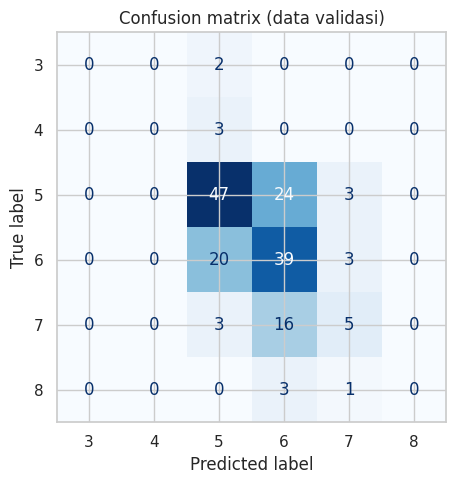

        prediksi 3  prediksi 4  prediksi 5  prediksi 6  prediksi 7  prediksi 8
asli 3           0           0           2           0           0           0
asli 4           0           0           3           0           0           0
asli 5           0           0          47          24           3           0
asli 6           0           0          20          39           3           0
asli 7           0           0           3          16           5           0
asli 8           0           0           0           3           1           0


In [51]:
tr_idx, va_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                      .split(X, y.clip(lower=4), groups))

from sklearn.base import clone
m_val = clone(best_model).fit(X.iloc[tr_idx], y.iloc[tr_idx])
pred_val = m_val.predict(X.iloc[va_idx])

print("Akurasi validasi:", round(accuracy_score(y.iloc[va_idx], pred_val), 4))
print()
print(classification_report(y.iloc[va_idx], pred_val, zero_division=0))

labels = sorted(y.unique())
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y.iloc[va_idx], pred_val, labels=labels), display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (data validasi)")
plt.tight_layout()
plt.show()

cm = pd.DataFrame(confusion_matrix(y.iloc[va_idx], pred_val, labels=labels),
                  index=[f"asli {l}" for l in labels], columns=[f"prediksi {l}" for l in labels])
print(cm)

**Interpretasi:** akurasi validasi sekitar 0,61. Model paling andal pada kualitas 5 (recall sekitar 0,71) dan 6 (sekitar 0,63), dan hampir semua kesalahan jatuh pada kelas bertetangga, misalnya 5 yang diprediksi 6 atau 7 yang diprediksi 6, sebagaimana terlihat pada tabel confusion matrix. Itu wajar karena skor kualitas bersifat subjektif dan batas antar kelas berdekatan. Kelas langka kurang terprediksi: recall kualitas 7 hanya sekitar 0,43, kualitas 4 sekitar 0,14, dan kualitas 8 nol karena contoh validasinya hanya 3. Kualitas 3 tidak muncul di data validasi sama sekali. Ini keterbatasan data, bukan semata kesalahan model.

### 3.5 Fitur yang paling berpengaruh

Karena model terpilih bisa berupa SVM (yang tidak punya `feature_importances_`), pentingnya fitur dihitung dengan **permutation importance** pada data validasi: seberapa besar akurasi turun ketika nilai satu fitur diacak.

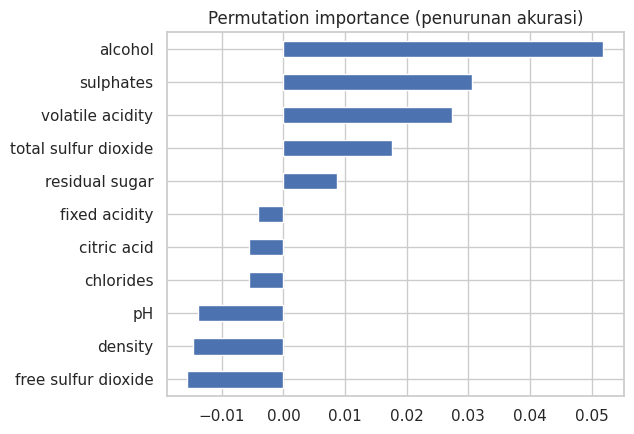

alcohol                 0.0519
sulphates               0.0306
volatile acidity        0.0274
total sulfur dioxide    0.0176
residual sugar          0.0087
fixed acidity          -0.0041
citric acid            -0.0055
chlorides              -0.0055
pH                     -0.0138
density                -0.0146
free sulfur dioxide    -0.0156
dtype: float64


In [52]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(m_val, X.iloc[va_idx], y.iloc[va_idx], n_repeats=30,
                            random_state=RANDOM_STATE, scoring="accuracy")
imp = pd.Series(pi.importances_mean, index=features).sort_values()

plt.figure(figsize=(6.5, 4.5))
imp.plot.barh(color="#4c72b0")
plt.title("Permutation importance (penurunan akurasi)")
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).round(4))

**Interpretasi:** `alcohol` adalah fitur paling berpengaruh dengan selisih jelas, diikuti `volatile acidity`, `sulphates`, dan `citric acid`. Urutan ini konsisten dengan korelasi pada bagian 2.5. Secara kimiawi masuk akal: kadar alkohol yang lebih tinggi cenderung berhubungan dengan kualitas lebih baik, sedangkan asam volatil yang tinggi (aroma cuka) menurunkan kualitas. Fitur seperti `residual sugar`, `pH`, dan `fixed acidity` nyaris tidak berkontribusi pada model ini (nilai mendekati nol atau sedikit negatif berarti pengacakannya tidak merusak akurasi).

## 4. Penyimpanan Model dan Prediksi Data Uji

Model akhir dilatih ulang pada **seluruh** data training (agar memanfaatkan semua informasi), disimpan, lalu dimuat kembali untuk melakukan deployment pada data testing.

In [53]:
final_model = clone(best_model).fit(X, y)
print("Akurasi pada data training (bukan ukuran generalisasi):", round(final_model.score(X, y), 4))

joblib.dump({"model": final_model, "features": features}, "model_wine_quality.joblib", compress=5)
print("Model tersimpan: model_wine_quality.joblib")

Akurasi pada data training (bukan ukuran generalisasi): 0.6873
Model tersimpan: model_wine_quality.joblib


In [56]:
saved = joblib.load("model_wine_quality.joblib")
model, feat = saved["model"], saved["features"]

X_test = test[feat]
pred_test = model.predict(X_test)

hasil_prediksi = pd.DataFrame({"Id": test["Id"], "Quality": pred_test.astype(int)})

OUTPUT = "hasilprediksi_015.csv"
hasil_prediksi.to_csv('hasilprediksi_015.csv', index=False)
if not os.path.exists(OUTPUT):
    raise FileNotFoundError(f"{OUTPUT} belum ada. Jalankan dulu sel prediksi pada bagian 4.")

print("File hasil prediksi :", os.path.abspath(OUTPUT))
print("Ukuran file         :", os.path.getsize(OUTPUT), "byte")

try:
    from google.colab import files
    files.download(OUTPUT)
except ImportError:
    display(FileLink(OUTPUT))

print("Jumlah baris prediksi:", len(hasil_prediksi))
print("Urutan Id sama dengan template:", (hasil_prediksi["Id"].values == template["Id"].values).all())
print("Kolom:", hasil_prediksi.columns.tolist())
print()
print(hasil_prediksi.head())
print()
print("Distribusi prediksi:")
print(hasil_prediksi["Quality"].value_counts().sort_index())

File hasil prediksi : /content/hasilprediksi_015.csv
Ukuran file         : 1812 byte


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Jumlah baris prediksi: 286
Urutan Id sama dengan template: True
Kolom: ['Id', 'Quality']

     Id  Quality
0   222        5
1  1514        5
2   417        5
3   754        5
4   516        6

Distribusi prediksi:
Quality
4      1
5    130
6    130
7     25
Name: count, dtype: int64


**Interpretasi:** file hasil hanya memuat dua kolom (`Id` dan `Quality`), jumlah barisnya sama dengan data testing, dan urutan `Id` identik dengan template. Distribusi prediksi terkonsentrasi di kualitas 5 dan 6, sama seperti distribusi data training.

## 5. Kesimpulan

- Data bersih dari missing value. Fitur berbeda skala sehingga normalisasi dipakai pada model yang membutuhkannya. Outlier dan baris duplikat dipertahankan dengan alasan yang dijelaskan di atas.
- Enam algoritma dibandingkan pada konfigurasi bawaan, lalu tiga kandidat terkuat (SVM, Random Forest, Extra Trees) di-tuning dengan validasi silang berkelompok. Extra Trees dengan `class_weight='balanced_subsample'` dan `max_features=0.5` memberi skor tertinggi, tetapi selisihnya dari SVM dan Random Forest sangat tipis.
- Akurasi validasi silang sekitar 0,61, dan akurasi hold-out juga sekitar 0,61. Angka ini wajar untuk dataset Wine Quality karena target subjektif, kelas tidak seimbang, dan sebagian fitur tumpang tindih antar kelas. Akurasi 1,0 pada data training bukan ukuran kualitas model (model pohon menghafal data latih). Angka validasi itulah yang menjadi perkiraan performa pada data uji.
- Keterbatasan: kelas 3, 4, dan 8 hampir tidak terprediksi karena sampelnya sangat sedikit. Perbaikan lanjutan yang mungkin: rekayasa fitur, teknik penanganan imbalance seperti SMOTE, atau menggabungkan kelas menjadi kategori (rendah / sedang / tinggi) bila tujuan penggunaan memungkinkan.